# SpatialLeiden parameter scan: RNA + spatial and MSI + spatial (one section)

For the sections in `SCAN_SECTIONS` (default: C1), each modality is clustered together with the spatial graph by `spatialleiden.multiplex_leiden` over a grid of
- **resolution** of the modality layer (`RESOLUTIONS`; the spatial layer uses the same resolution unless `SPATIAL_RESOLUTION` is set), and
- **layer ratio** = weight of the spatial layer relative to the modality layer (`SPATIAL_RATIOS`; modality weight 1, spatial weight = ratio; 0 = no spatial layer).

Input is the MuData written by `04_all_fmp10_slides.ipynb` (`MSI_PREPROCESSING` selects the variant). The modality embeddings and kNN graphs are rebuilt **within the scanned sections only** (RNA: PCA on the highly variable genes; MSI: PCA on all m/z; Harmony over sections if more than one section is scanned), so the scan is a single-sample analysis. The spatial graph is the Visium grid (six direct neighbours, no edges between sections).

The scan is descriptive: no grid point is selected. The main output is a grid of cluster maps per modality (rows: weight ratio, columns: resolution; `MAP_RATIOS`, `MAP_RESOLUTIONS`). MSI + spatial is clustered on the spots with MSI only (spots without MSI are grey). For orientation, every grid point also gets the number of clusters and ARIs against the annotation (on the annotated spots with MSI, the same spots for both modalities); note that within one section the two CPs are spatially separate, so a strong spatial layer alone can split intact from lesioned CP. One Leiden seed per grid point (`SEEDS`). Results: `results/Cosie_Clustering/<DATASET>/msi_<MSI_PREPROCESSING>/param_scan_<sections>/`.

In [1]:
import itertools
import warnings
from pathlib import Path

import anndata as ad
import harmonypy
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
from sklearn.metrics import adjusted_rand_score
from spatialleiden import multiplex_leiden

warnings.filterwarnings("ignore", category=FutureWarning)

# Configuration

In [2]:
DATASET = "striatum"
MSI_PREPROCESSING = "log"   # which run of notebook 04 to load ("log" or "maldipy")
SCAN_SECTIONS = ["V11L12-109_C1"]  # e.g. ["V11L12-109_A1"], ["V11L12-109_B1"] or several sections (then clustered jointly)
LESION_REGION_NAME = "CP"   # lesion region of this slide (label used in the plots)

RESOLUTIONS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5, 1.8, 2.2, 2.6, 3.0]  # resolution of the modality layer
SPATIAL_RATIOS = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]                    # spatial weight / modality weight
SPATIAL_RESOLUTION = None   # None = same resolution as the modality layer; a number = fixed spatial resolution
SEEDS = [42]                # Leiden seeds per grid point
MAP_RESOLUTIONS = [0.2, 0.4, 0.6, 0.8, 1.0, 1.5, 2.2, 3.0]  # columns of the cluster-map grids (subset of RESOLUTIONS)
MAP_RATIOS = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0]               # rows of the cluster-map grids (subset of SPATIAL_RATIOS)
assert set(MAP_RESOLUTIONS) <= set(RESOLUTIONS) and set(MAP_RATIOS) <= set(SPATIAL_RATIOS), "map grid must be a subset of the scan grid"

n_pcs = {"rna": 50, "msi": 30}
n_neighbors = 15
seed = 42

in_file = Path("../results/Cosie_Clustering") / DATASET / f"msi_{MSI_PREPROCESSING}" / f"mouse_brain_6OHDA_{DATASET}.h5mu"
tag = "_".join(s.split("_")[1] for s in SCAN_SECTIONS)
out_dir = in_file.parent / f"param_scan_{tag}"
out_dir.mkdir(parents=True, exist_ok=True)
print("input:", in_file, "| output:", out_dir)

input: ../results/Cosie_Clustering/striatum/msi_log/mouse_brain_6OHDA_striatum.h5mu | output: ../results/Cosie_Clustering/striatum/msi_log/param_scan_C1


# Load data and build the graphs of the scanned sections

In [3]:
mdata = md.read_h5mu(in_file)
obs = mdata.obs
spots = obs.index[obs["section"].isin(SCAN_SECTIONS)]        # all spots of the scanned sections (RNA everywhere)
rna = mdata["rna"][spots].copy()
msi_spots = mdata["msi"].obs_names[mdata["msi"].obs["section"].isin(SCAN_SECTIONS).to_numpy()]
msi = mdata["msi"][msi_spots].copy()
print(f"{len(spots):,} spots, {len(msi_spots):,} with MSI, sections: {SCAN_SECTIONS}")


def embedding(a, n_comps, mask_var=None):
    # PCA fitted on the scanned sections only; Harmony over sections if more than one is scanned
    sc.pp.pca(a, n_comps=n_comps, mask_var=mask_var, random_state=seed)
    if a.obs["section"].nunique() > 1:
        ho = harmonypy.run_harmony(a.obsm["X_pca"], a.obs[["section"]], "section", random_state=seed, verbose=False)
        Z = np.asarray(ho.Z_corr)
        return Z if Z.shape[0] == a.n_obs else Z.T
    return a.obsm["X_pca"]


def knn_graph(emb, names):
    # kNN graph on emb, padded to all spots of the scanned sections (spots without the modality have no edges)
    a = ad.AnnData(obs=pd.DataFrame(index=names), obsm={"emb": np.asarray(emb)})
    sc.pp.neighbors(a, n_neighbors=n_neighbors, use_rep="emb", random_state=seed)
    idx = pd.Index(spots).get_indexer(names)
    g = a.obsp["connectivities"].tocoo()
    return sp.csr_matrix((g.data, (idx[g.row], idx[g.col])), shape=(len(spots), len(spots)))


rna.obs["section"] = obs.loc[rna.obs_names, "section"].astype(str).to_numpy()
msi.obs["section"] = obs.loc[msi.obs_names, "section"].astype(str).to_numpy()
graphs = {
    "rna": knn_graph(embedding(rna, n_pcs["rna"], mask_var="highly_variable"), rna.obs_names),
    "msi": knn_graph(embedding(msi, n_pcs["msi"]), msi.obs_names),
    "spatial": mdata.obsp["spatial_connectivities"][obs.index.get_indexer(spots)][:, obs.index.get_indexer(spots)],
}
for name, g in graphs.items():
    print(f"{name}: {g.nnz:,} edges, spots with edges: {(np.asarray(g.sum(axis=1)).ravel() > 0).sum():,}")

# scored spots: annotated and with MSI (the same spots for both modalities)
sub = obs.loc[spots]
scored = (sub["has_msi"] & sub["RegionLoupe"].notna() & sub["lesion"].notna()).to_numpy()
in_region = sub["in_lesion_region"].to_numpy()
region = sub["RegionLoupe"].astype(str)
truth = {
    "ARI region": region.to_numpy(),
    "ARI lesion": sub["lesion"].astype(str).to_numpy(),
    "ARI region+local lesion": region.where(~sub["in_lesion_region"], region + "_" + sub["lesion"].astype(str)).to_numpy(),
}
print(f"scored spots: {scored.sum():,} (of which {(scored & in_region).sum():,} in {LESION_REGION_NAME})")

2,918 spots, 2,379 with MSI, sections: ['V11L12-109_C1']


/dh-projects/ag-ishaque/analysis/malta/envs/envs/spatialleiden_SL2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


rna: 70,576 edges, spots with edges: 2,918
msi: 51,468 edges, spots with edges: 2,379
spatial: 17,010 edges, spots with edges: 2,918
scored spots: 2,273 (of which 660 in CP)


# Parameter scan

`multiplex_leiden([modality, spatial])` with partition resolutions `(r, r_spatial)` and layer weights `(1, ratio)`; ratio 0 clusters the modality layer alone.

In [4]:
# spots clustered per modality: RNA on all spots, MSI on the spots with MSI only (others would be isolated nodes)
nodes = {"rna": np.ones(len(spots), dtype=bool), "msi": sub["has_msi"].to_numpy()}


def cluster(modality, res, ratio, s):
    # labels for all spots of the scanned sections; spots outside nodes[modality] get -1
    keep = nodes[modality]
    r_sp = res if SPATIAL_RESOLUTION is None else SPATIAL_RESOLUTION
    layers = [graphs[modality][keep][:, keep]] + ([graphs["spatial"][keep][:, keep]] if ratio > 0 else [])
    lab = multiplex_leiden(
        *layers,
        partition_kwargs=[{"resolution_parameter": res}] + ([{"resolution_parameter": r_sp}] if ratio > 0 else []),
        layer_weights=[1.0] + ([ratio] if ratio > 0 else []),
        directed=False, n_iterations=5, random_state=s,
    )
    labels = np.full(len(spots), -1)
    labels[keep] = np.asarray(lab)
    return labels


def score(labels):
    lab = labels[scored]
    out = {"n_clusters": len(np.unique(labels[labels >= 0]))}
    for name, t in truth.items():
        out[name] = adjusted_rand_score(t[scored], lab)
    m = scored & in_region
    out[f"ARI lesion in {LESION_REGION_NAME}"] = adjusted_rand_score(truth["ARI lesion"][m], labels[m])
    return out


records, all_labels = [], {}
for modality in ["rna", "msi"]:
    for res, ratio, s in itertools.product(RESOLUTIONS, SPATIAL_RATIOS, SEEDS):
        labels = cluster(modality, res, ratio, s)
        all_labels[modality, res, ratio, s] = labels
        records.append({"modality": modality, "resolution": res, "spatial ratio": ratio, "seed": s, **score(labels)})
    print(modality, "done")
scan = pd.DataFrame(records)
scan.to_csv(out_dir / "param_scan_scores.csv", index=False)
scan.groupby("modality")[["n_clusters"]].describe().round(1)

rna done
msi done


n_clusters                                       
              count  mean   std  min  25%  50%   75%   max
modality                                                  
msi           126.0  13.6  13.4  1.0  3.0  6.5  23.0  50.0
rna           126.0  11.1   7.9  2.0  4.0  9.0  16.0  32.0

## Heatmaps

Descriptive overview: one row per modality, one column per quantity; x: resolution, y: spatial/modality weight ratio (mean over seeds). Numbers are printed for the number of clusters only; the ARIs are shown by colour.

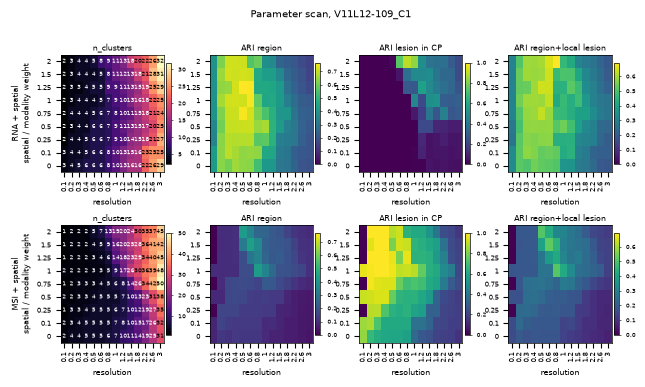

In [5]:
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"], "font.size": 6,
    "axes.titlesize": 6, "axes.labelsize": 6, "xtick.labelsize": 5, "ytick.labelsize": 5,
    "axes.linewidth": 0.5, "pdf.fonttype": 42, "svg.fonttype": "none",
})
mm = 1 / 25.4
plot_metrics = ["n_clusters", "ARI region", f"ARI lesion in {LESION_REGION_NAME}", "ARI region+local lesion"]
mean = scan.groupby(["modality", "spatial ratio", "resolution"])[plot_metrics].mean()
fig, axes = plt.subplots(2, len(plot_metrics), figsize=(183 * mm, 95 * mm), gridspec_kw={"wspace": 0.35, "hspace": 0.45})
for row, (modality, title) in enumerate([("rna", "RNA + spatial"), ("msi", "MSI + spatial")]):
    for col, metric in enumerate(plot_metrics):
        ax = axes[row, col]
        mat = mean.loc[modality, metric].unstack("resolution").reindex(index=SPATIAL_RATIOS, columns=RESOLUTIONS)
        vmax = None if metric == "n_clusters" else max(0.05, scan[metric].max())
        im = ax.imshow(mat.to_numpy(), aspect="auto", origin="lower", cmap="magma" if metric == "n_clusters" else "viridis",
                       vmin=None if metric == "n_clusters" else 0, vmax=vmax)
        if metric == "n_clusters":
            for (i, j), val in np.ndenumerate(mat.to_numpy()):
                ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=4,
                        color="white" if val < np.nanmax(mat.to_numpy()) * 0.6 else "black")
        ax.set_xticks(range(len(RESOLUTIONS)))
        ax.set_xticklabels([f"{r:g}" for r in RESOLUTIONS], rotation=90)
        ax.set_yticks(range(len(SPATIAL_RATIOS)))
        ax.set_yticklabels([f"{r:g}" for r in SPATIAL_RATIOS])
        ax.set_xlabel("resolution")
        if col == 0:
            ax.set_ylabel(f"{title}\nspatial / modality weight")
        ax.set_title(metric, pad=3)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.02).ax.tick_params(labelsize=4, width=0.4, length=1.5)
fig.suptitle(f"Parameter scan, {', '.join(SCAN_SECTIONS)}", fontsize=7, y=1.0)
fig.savefig(out_dir / "param_scan_heatmaps.pdf", dpi=600, bbox_inches="tight")
fig.savefig(out_dir / "param_scan_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

## Cluster maps over the grid

One figure per modality and scanned section: rows = spatial/modality weight ratio (`MAP_RATIOS`), columns = resolution (`MAP_RESOLUTIONS`), first seed. Every cluster has the colour of the region it overlaps most; further clusters of the same region get own colours (e.g. intact vs lesioned CP); grey = spots not clustered (MSI: no MSI). The last column is the region annotation. Above each map: number of clusters.

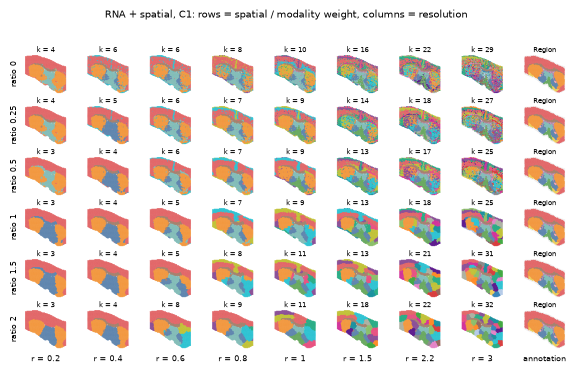

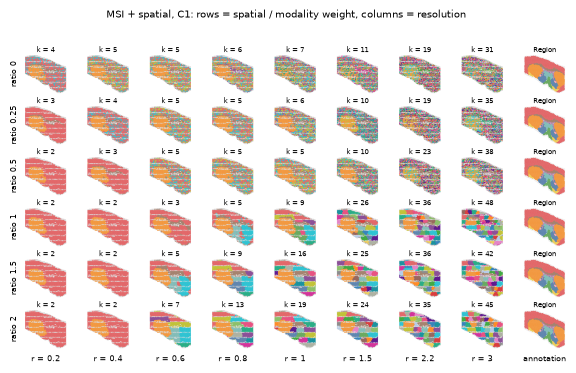

In [6]:
REGION_COLORS = ["#4E79A7", "#F28E2B", "#E15759", "#76B7B2", "#59A14F", "#EDC948", "#B07AA1", "#FF9DA7", "#9C755F"]
EXTRA_COLORS = ["#17BECF", "#BCBD22", "#7F3C8D", "#11A579", "#E73F74", "#80BA5A", "#008695", "#CF1C90", "#A5AA99",
                "#4b0082", "#ff7f0e", "#2ca02c", "#d62728", "#8c564b", "#e377c2", "#7f7f7f", "#1f77b4", "#aec7e8"]
regions = sorted(sub["RegionLoupe"].dropna().astype(str).unique())
region_color = dict(zip(regions, REGION_COLORS + EXTRA_COLORS))
xy = pd.DataFrame(np.asarray(mdata.obsm["spatial"]), index=mdata.obs_names, columns=["x", "y"]).loc[spots]
known = (sub["RegionLoupe"].notna() & sub["lesion"].notna()).to_numpy()


def cluster_colors(labels):
    ok = known & (labels >= 0)
    counts = pd.crosstab(labels[ok], region.to_numpy()[ok])
    reg, size = counts.idxmax(axis=1), counts.max(axis=1)
    colors, used, extra = {}, set(), itertools.cycle(EXTRA_COLORS)
    for c in size.sort_values(ascending=False).index:
        colors[c] = next(extra) if reg[c] in used else region_color[reg[c]]
        used.add(reg[c])
    return colors


for modality, name in [("rna", "RNA + spatial"), ("msi", "MSI + spatial")]:
    for section in SCAN_SECTIONS:
        sel = (sub["section"] == section).to_numpy()
        fig, axes = plt.subplots(len(MAP_RATIOS), len(MAP_RESOLUTIONS) + 1,
                                 figsize=(183 * mm, 183 * mm * len(MAP_RATIOS) / (len(MAP_RESOLUTIONS) + 1) * 0.8), squeeze=False,
                                 gridspec_kw={"wspace": 0.05, "hspace": 0.25})
        for i, ratio in enumerate(MAP_RATIOS):
            for j, res in enumerate(MAP_RESOLUTIONS):
                labels = all_labels[modality, res, ratio, SEEDS[0]]
                colors = cluster_colors(labels)
                ax = axes[i, j]
                ax.scatter(xy["x"][sel], xy["y"][sel], s=0.4, c=[colors.get(l, "#d9d9d9") for l in labels[sel]],
                           linewidth=0, rasterized=True)
                ax.set_title(f"k = {len(np.unique(labels[sel & (labels >= 0)]))}", pad=1, fontsize=5)
            ax = axes[i, -1]
            ax.scatter(xy["x"][sel], xy["y"][sel], s=0.4, c=[region_color.get(r, "#f0f0f0") for r in region[sel]],
                       linewidth=0, rasterized=True)
            ax.set_title("Region", pad=1, fontsize=5)
        for ax in axes.ravel():
            ax.set_aspect(1)
            ax.invert_yaxis()
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(False)
        for j, res in enumerate(MAP_RESOLUTIONS):
            axes[-1, j].set_xlabel(f"r = {res:g}", fontsize=5.5)
        axes[-1, -1].set_xlabel("annotation", fontsize=5.5)
        for i, ratio in enumerate(MAP_RATIOS):
            axes[i, 0].set_ylabel(f"ratio {ratio:g}", fontsize=5.5)
        sec = section.split("_")[1]
        fig.suptitle(f"{name}, {sec}: rows = spatial / modality weight, columns = resolution", fontsize=7, y=0.995)
        fig.savefig(out_dir / f"param_scan_maps_{modality}_{sec}.pdf", dpi=600, bbox_inches="tight")
        fig.savefig(out_dir / f"param_scan_maps_{modality}_{sec}.png", dpi=300, bbox_inches="tight")
        plt.show()